In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:

df = pd.read_csv("Heart_Disease_Prediction.csv")

df.head()


,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presence
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,Absence
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,Presence
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,Absence
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,Absence


In [3]:

print("Dataset Shape:", df.shape)


Dataset Shape: (270, 14)


In [4]:

print(df.isnull().sum())


Age                        0
Sex                        0
Chest pain type            0
BP                         0
Cholesterol                0
FBS over 120               0
EKG results                0
Max HR                     0
Exercise angina            0
ST depression              0
Slope of ST                0
Number of vessels fluro    0
Thallium                   0
Heart Disease              0
dtype: int64


In [5]:

print(df["Heart Disease"].value_counts())


Heart Disease
Absence     150
Presence    120
Name: count, dtype: int64


In [6]:

df["Heart Disease"] = df["Heart Disease"].map({
    "Presence": 1,
    "Absence": 0
})

print(df["Heart Disease"].value_counts())


Heart Disease
0    150
1    120
Name: count, dtype: int64


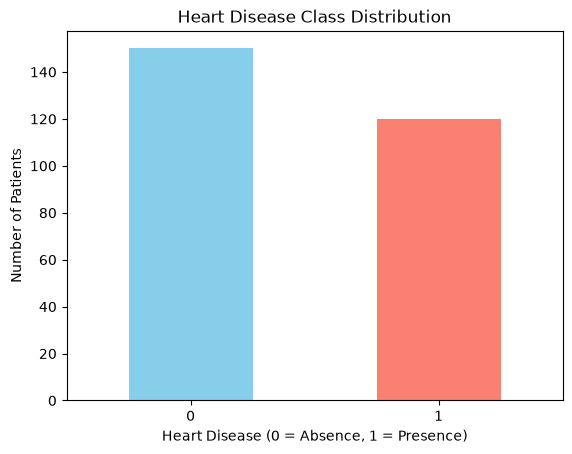

In [7]:

df["Heart Disease"].value_counts().sort_index().plot(
    kind="bar",
    color=["skyblue", "salmon"]
)

plt.title("Heart Disease Class Distribution")
plt.xlabel("Heart Disease (0 = Absence, 1 = Presence)")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.show()


In [8]:

X = df.drop("Heart Disease", axis=1)
y = df["Heart Disease"]

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)


Input Shape: (270, 13)
Output Shape: (270,)


In [9]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)



Training Data: (216, 13)
Testing Data: (54, 13)


In [10]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Scaled:", X_train_scaled.shape)
print("Testing Scaled:", X_test_scaled.shape)


Training Scaled: (216, 13)
Testing Scaled: (54, 13)


In [11]:

from sklearn.linear_model import LogisticRegression

# Create model
lr_model = LogisticRegression(max_iter=1000)

# Train model
lr_model.fit(X_train_scaled, y_train)

# Make predictions
lr_pred = lr_model.predict(X_test_scaled)

print("Predictions:", lr_pred)


Predictions: [0 0 0 1 0 0 0 1 1 1 0 1 0 1 1 1 0 1 0 1 0 1 0 0 0 1 0 0 0 1 0 1 1 1 0 0 1
 0 0 0 1 0 1 1 1 0 1 1 1 1 1 1 0 1]


In [12]:

%pip install scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Boss\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [13]:

from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)

print("Predictions:", lr_pred)


Predictions: [0 0 0 1 0 0 0 1 1 1 0 1 0 1 1 1 0 1 0 1 0 1 0 0 0 1 0 0 0 1 0 1 1 1 0 0 1
 0 0 0 1 0 1 1 1 0 1 1 1 1 1 1 0 1]


In [14]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, lr_pred))
print("Precision:", precision_score(y_test, lr_pred))
print("Recall:", recall_score(y_test, lr_pred))
print("F1 Score:", f1_score(y_test, lr_pred))


Accuracy: 0.8518518518518519
Precision: 0.7857142857142857
Recall: 0.9166666666666666
F1 Score: 0.8461538461538461


In [15]:

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Predictions:", dt_pred)


Predictions: [0 0 0 1 0 0 0 1 1 1 0 1 0 1 1 1 0 1 0 1 0 1 0 0 0 1 1 0 0 1 0 0 1 0 0 1 1
 0 0 0 1 0 1 1 1 1 0 1 1 0 1 1 0 1]


In [16]:

print("Decision Tree Results:")

print("Accuracy:", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall:", recall_score(y_test, dt_pred))
print("F1 Score:", f1_score(y_test, dt_pred))


Decision Tree Results:
Accuracy: 0.7962962962962963
Precision: 0.7407407407407407
Recall: 0.8333333333333334
F1 Score: 0.7843137254901961


In [17]:

results = []

results.append({
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, lr_pred),
    "Precision": precision_score(y_test, lr_pred),
    "Recall": recall_score(y_test, lr_pred),
    "F1-Score": f1_score(y_test, lr_pred)
})

results.append({
    "Model": "Decision Tree",
    "Accuracy": accuracy_score(y_test, dt_pred),
    "Precision": precision_score(y_test, dt_pred),
    "Recall": recall_score(y_test, dt_pred),
    "F1-Score": f1_score(y_test, dt_pred)
})

pd.DataFrame(results).round(4)


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8519,0.7857,0.9167,0.8462
1,Decision Tree,0.7963,0.7407,0.8333,0.7843


In [18]:

from sklearn.svm import SVC

# Create SVM model
svm_model = SVC(kernel="rbf")

# Train model
svm_model.fit(X_train_scaled, y_train)

# Make predictions
svm_pred = svm_model.predict(X_test_scaled)

print("SVM Predictions:", svm_pred)


SVM Predictions: [0 0 0 1 0 0 0 1 0 1 0 0 0 1 1 1 0 1 0 1 0 1 0 0 0 1 0 0 0 1 0 1 1 0 0 1 1
 0 1 0 1 0 1 1 1 0 1 1 1 0 1 1 0 1]


In [19]:

svm_accuracy = accuracy_score(y_test, svm_pred)
svm_precision = precision_score(y_test, svm_pred)
svm_recall = recall_score(y_test, svm_pred)
svm_f1 = f1_score(y_test, svm_pred)

print("SVM Results:")
print("Accuracy:", svm_accuracy)
print("Precision:", svm_precision)
print("Recall:", svm_recall)
print("F1 Score:", svm_f1)


SVM Results:
Accuracy: 0.8148148148148148
Precision: 0.7692307692307693
Recall: 0.8333333333333334
F1 Score: 0.8


In [20]:

from sklearn.neighbors import KNeighborsClassifier

# Create KNN model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train model
knn_model.fit(X_train_scaled, y_train)

# Make predictions
knn_pred = knn_model.predict(X_test_scaled)

print("KNN Predictions:", knn_pred)


KNN Predictions: [0 0 0 1 0 0 0 1 0 1 1 0 0 1 1 1 0 1 0 1 0 1 0 0 0 1 1 0 0 1 0 1 1 0 0 1 1
 0 1 0 1 0 1 1 1 0 0 1 1 1 1 1 1 1]


In [21]:

knn_accuracy = accuracy_score(y_test, knn_pred)
knn_precision = precision_score(y_test, knn_pred)
knn_recall = recall_score(y_test, knn_pred)
knn_f1 = f1_score(y_test, knn_pred)

print("KNN Results:")
print("Accuracy:", knn_accuracy)
print("Precision:", knn_precision)
print("Recall:", knn_recall)
print("F1 Score:", knn_f1)


KNN Results:
Accuracy: 0.7962962962962963
Precision: 0.7241379310344828
Recall: 0.875
F1 Score: 0.7924528301886793


In [22]:

results.append({
    "Model": "SVM",
    "Accuracy": svm_accuracy,
    "Precision": svm_precision,
    "Recall": svm_recall,
    "F1-Score": svm_f1
})

results.append({
    "Model": "KNN",
    "Accuracy": knn_accuracy,
    "Precision": knn_precision,
    "Recall": knn_recall,
    "F1-Score": knn_f1
})

pd.DataFrame(results).round(4)


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8519,0.7857,0.9167,0.8462
1,Decision Tree,0.7963,0.7407,0.8333,0.7843
2,SVM,0.8148,0.7692,0.8333,0.8000
3,KNN,0.7963,0.7241,0.8750,0.7925


In [23]:




nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

nb_pred = nb_model.predict(X_test)


NameError: name 'GaussianNB' is not defined

In [24]:

from sklearn.naive_bayes import GaussianNB

# Create model
nb_model = GaussianNB()

# Train model
nb_model.fit(X_train, y_train)

# Make predictions
nb_pred = nb_model.predict(X_test)

print("Predictions:", nb_pred)


Predictions: [0 0 0 1 0 0 0 1 1 1 0 0 0 1 1 1 0 1 0 1 0 1 0 0 0 1 0 0 0 1 0 1 1 0 0 0 1
 0 0 0 1 0 1 1 1 0 1 1 1 1 1 1 0 1]


In [25]:

print("Naive Bayes Results:")

print("Accuracy:", accuracy_score(y_test, nb_pred))
print("Precision:", precision_score(y_test, nb_pred))
print("Recall:", recall_score(y_test, nb_pred))
print("F1 Score:", f1_score(y_test, nb_pred))


Naive Bayes Results:
Accuracy: 0.8518518518518519
Precision: 0.8076923076923077
Recall: 0.875
F1 Score: 0.84


In [26]:

from sklearn.ensemble import RandomForestClassifier

# Create model with 100 trees
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train model
rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)

print("Random Forest Predictions:", rf_pred)


Random Forest Predictions: [0 0 0 1 0 0 0 1 1 1 0 0 0 1 1 1 0 1 0 1 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 1 1
 0 0 0 1 0 1 1 1 0 0 1 1 0 1 1 0 1]


In [27]:

print("Random Forest Results:")

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))


Random Forest Results:
Accuracy: 0.8148148148148148
Precision: 0.7692307692307693
Recall: 0.8333333333333334
F1 Score: 0.8


In [28]:

from sklearn.ensemble import GradientBoostingClassifier

# Create model
gb_model = GradientBoostingClassifier(random_state=42)

# Train model
gb_model.fit(X_train, y_train)

# Make predictions
gb_pred = gb_model.predict(X_test)

print("Gradient Boosting Predictions:", gb_pred)


Gradient Boosting Predictions: [0 0 0 1 0 0 0 1 1 1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 1 1
 0 0 0 1 0 1 1 1 0 1 1 1 0 1 1 0 1]


In [29]:

gb_accuracy = accuracy_score(y_test, gb_pred)
gb_precision = precision_score(y_test, gb_pred)
gb_recall = recall_score(y_test, gb_pred)
gb_f1 = f1_score(y_test, gb_pred)

print("Gradient Boosting Results:")
print("Accuracy:", gb_accuracy)
print("Precision:", gb_precision)
print("Recall:", gb_recall)
print("F1 Score:", gb_f1)


Gradient Boosting Results:
Accuracy: 0.8148148148148148
Precision: 0.75
Recall: 0.875
F1 Score: 0.8076923076923077


In [30]:

from sklearn.ensemble import AdaBoostClassifier

# Create model
ada_model = AdaBoostClassifier(random_state=42)

# Train model
ada_model.fit(X_train, y_train)

# Make predictions
ada_pred = ada_model.predict(X_test)

print("AdaBoost Predictions:", ada_pred)


AdaBoost Predictions: [0 0 0 1 0 0 0 1 1 1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 0 1 1 0 0 1 0 1 1 1 0 0 1
 0 1 0 1 0 1 1 1 0 0 1 1 0 1 1 0 1]


In [32]:

ada_accuracy = accuracy_score(y_test, ada_pred)
ada_precision = precision_score(y_test, ada_pred)
ada_recall = recall_score(y_test, ada_pred)
ada_f1 = f1_score(y_test, ada_pred)

print("AdaBoost Results:")
print("Accuracy:", ada_accuracy)
print("Precision:", ada_precision)
print("Recall:", ada_recall)
print("F1 Score:", ada_f1)


AdaBoost Results:
Accuracy: 0.8333333333333334
Precision: 0.7586206896551724
Recall: 0.9166666666666666
F1 Score: 0.8301886792452831


In [33]:

results.append({
    "Model": "Gradient Boosting",
    "Accuracy": gb_accuracy,
    "Precision": gb_precision,
    "Recall": gb_recall,
    "F1-Score": gb_f1
})

results.append({
    "Model": "AdaBoost",
    "Accuracy": ada_accuracy,
    "Precision": ada_precision,
    "Recall": ada_recall,
    "F1-Score": ada_f1
})

pd.DataFrame(results).round(4)


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8519,0.7857,0.9167,0.8462
1,Decision Tree,0.7963,0.7407,0.8333,0.7843
2,SVM,0.8148,0.7692,0.8333,0.8000
3,KNN,0.7963,0.7241,0.8750,0.7925
4,Gradient Boosting,0.8148,0.7500,0.8750,0.8077
5,AdaBoost,0.8333,0.7586,0.9167,0.8302


In [34]:

results.append({
    "Model": "Naive Bayes",
    "Accuracy": accuracy_score(y_test, nb_pred),
    "Precision": precision_score(y_test, nb_pred),
    "Recall": recall_score(y_test, nb_pred),
    "F1-Score": f1_score(y_test, nb_pred)
})

results.append({
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred),
    "Recall": recall_score(y_test, rf_pred),
    "F1-Score": f1_score(y_test, rf_pred)
})

pd.DataFrame(results).round(4)


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8519,0.7857,0.9167,0.8462
1,Decision Tree,0.7963,0.7407,0.8333,0.7843
2,SVM,0.8148,0.7692,0.8333,0.8000
3,KNN,0.7963,0.7241,0.8750,0.7925
4,Gradient Boosting,0.8148,0.7500,0.8750,0.8077
5,AdaBoost,0.8333,0.7586,0.9167,0.8302
6,Naive Bayes,0.8519,0.8077,0.8750,0.8400
7,Random Forest,0.8148,0.7692,0.8333,0.8000


In [35]:

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="Accuracy",
    ascending=False
)

display(comparison_df.round(4))


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8519,0.7857,0.9167,0.8462
6,Naive Bayes,0.8519,0.8077,0.8750,0.8400
5,AdaBoost,0.8333,0.7586,0.9167,0.8302
2,SVM,0.8148,0.7692,0.8333,0.8000
4,Gradient Boosting,0.8148,0.7500,0.8750,0.8077
7,Random Forest,0.8148,0.7692,0.8333,0.8000
3,KNN,0.7963,0.7241,0.8750,0.7925
1,Decision Tree,0.7963,0.7407,0.8333,0.7843


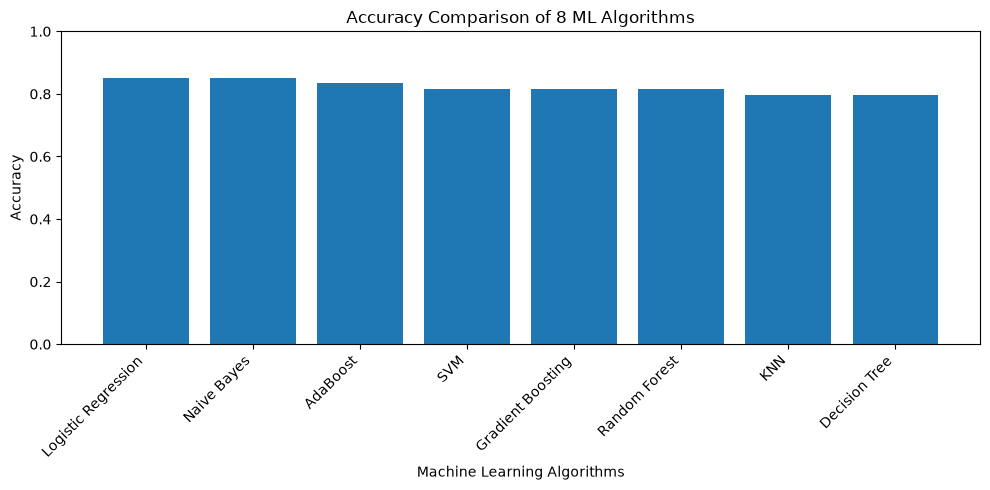

In [36]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Accuracy"]
)

plt.title("Accuracy Comparison of 8 ML Algorithms")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Accuracy")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


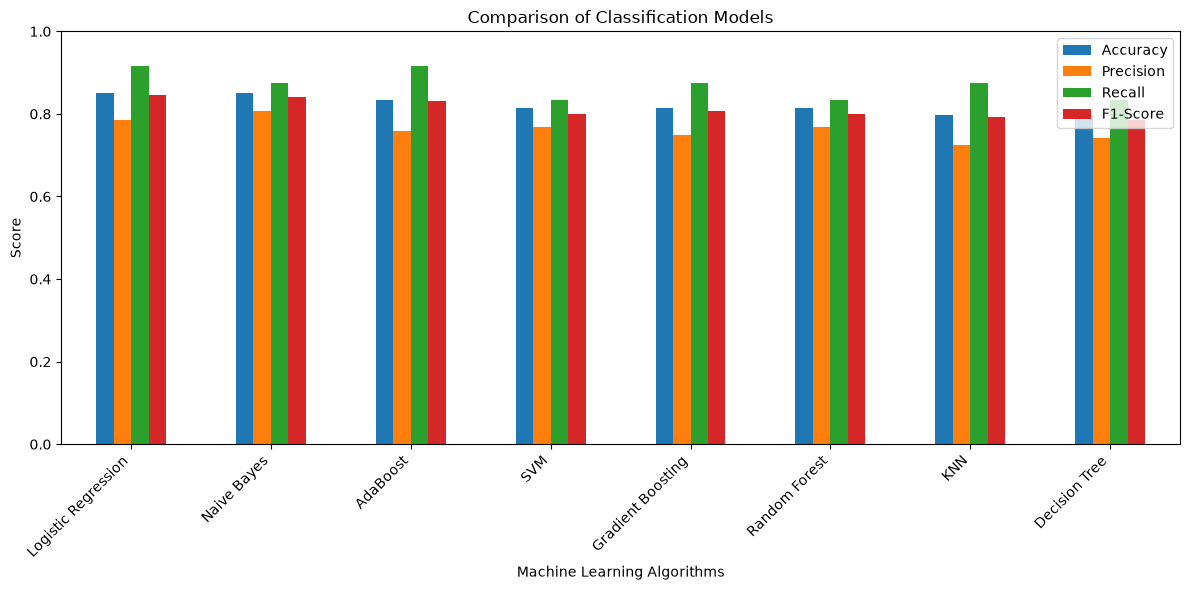

In [38]:

comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Comparison of Classification Models")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()


Final Conclusion:

Eight machine learning classification algorithms were trained and evaluated on the heart disease dataset. Logistic Regression and Naive Bayes achieved the highest accuracy of 85.19%. However, Logistic Regression achieved a higher recall of 91.67% and F1-score of 84.62%. Therefore, Logistic Regression was selected as the best overall model for this experiment based on its accuracy, recall, and F1-score.